# CardioIA, Fase 2, Ir Além 2: diagnóstico visual em cardiologia com rede neural (MLP em Keras)

| Item | Valor |
|---|---|
| Curso | FIAP, Inteligência Artificial, 2º ano |
| Fase | 2, "Diagnóstico Automatizado, IA no Estetoscópio Digital", atividade Ir Além 2 |
| Grupo | Grupo 69 |
| Integrantes | Silvio Prestes Guerreiro Junior (RM567958) |
| Tutor | Leonardo Ruiz Orabona |
| Coordenador | André Godoi Chiovato |

**Objetivo.** Usar um dataset público de eletrocardiogramas com classificação binária (normal vs. anormal), pré-processar as imagens dos batimentos (redimensionar e converter para tons de cinza), criar uma rede neural do tipo MLP (Perceptron Multicamadas) em Keras, treinar e testar o modelo e avaliar a acurácia.

**Ponto de atenção sobre o dataset.** O conjunto recomendado pelo enunciado (Kaggle, `shayanfazeli/heartbeat`) distribui os batimentos como **séries numéricas** de 187 amostras, e não como arquivos de imagem. Para atender literalmente à etapa de pré-processamento de imagens, cada batimento é primeiro **desenhado como uma imagem em tons de cinza** (o traçado do batimento em um quadro de 96 x 96 pixels, gravado em PNG), e só então as imagens são redimensionadas para 32 x 32, normalizadas e achatadas para alimentar a MLP. Ao final, a mesma MLP é treinada diretamente sobre o sinal numérico, para comparação.

**Aviso de uso acadêmico.** Exercício de disciplina com dados públicos anonimizados. Nenhum resultado aqui apresentado é ferramenta de diagnóstico, e nada substitui a avaliação de um profissional de saúde.

**Como executar.** Localmente: `pip install -r config/requirements.txt`, abrir este notebook a partir da pasta `src/notebooks/` e usar "Reiniciar e executar tudo". O dataset deve estar em `data/` (ver README e `data/LEIAME.md`); se os arquivos não forem encontrados, o notebook os obtém de um espelho público e confere o SHA-256. No Google Colab, executar antes, descomentadas:

```python
# !git clone https://github.com/silvioguerreiro/FIAP_2TIAOR_2026_Ano2_Fase2_Ir_Alem_2_Grupo69_-cardioia-ecg-mlp.git
# %cd FIAP_2TIAOR_2026_Ano2_Fase2_Ir_Alem_2_Grupo69_-cardioia-ecg-mlp/src/notebooks
```

## 1. Ambiente

Versões das bibliotecas e sementes fixas (`SEMENTE = 42` em NumPy, Python e TensorFlow), com operações determinísticas habilitadas no TensorFlow. Na mesma máquina, "Reiniciar e executar tudo" reproduz os mesmos números; entre máquinas ou versões diferentes das bibliotecas, as últimas casas decimais podem variar, sem alterar a estrutura dos resultados.

In [1]:
import hashlib
import os
import platform
import random
import time
import urllib.request
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # silencia o log em C++ do TensorFlow (excecoes do Python continuam visiveis)

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import sklearn
import tensorflow as tf
from PIL import Image
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             roc_auc_score)
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers

# Sementes fixas em todas as bibliotecas que usam aleatoriedade (reprodutibilidade)
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
tf.random.set_seed(SEMENTE)
keras.utils.set_random_seed(SEMENTE)
tf.config.experimental.enable_op_determinism()  # operacoes deterministicas: a mesma maquina reproduz os mesmos numeros


def localizar_raiz():
    """Sobe a partir da pasta atual ate encontrar a raiz do repositorio (pasta que contem config/requirements.txt e assets/)."""
    atual = Path.cwd().resolve()
    for candidato in [atual, *atual.parents]:
        if (candidato / "config" / "requirements.txt").exists() and (candidato / "assets").is_dir():
            return candidato
    raise FileNotFoundError("Raiz do repositorio nao encontrada; no Colab, clone o repositorio e entre em src/notebooks/.")


RAIZ = localizar_raiz()

# Pastas usadas pelo notebook: dataset em data/, figuras em assets/, exemplos PNG em assets/exemplos_imagens/, modelo em src/models/
DIR_DADOS = RAIZ / "data"
DIR_ASSETS = RAIZ / "assets"
DIR_MODELOS = RAIZ / "src" / "models"
DIR_EXEMPLOS = RAIZ / "assets" / "exemplos_imagens"
for pasta in (DIR_DADOS, DIR_ASSETS, DIR_MODELOS, DIR_EXEMPLOS):
    pasta.mkdir(exist_ok=True)

# Estilo unico para todas as figuras do notebook
CORES = {"normal": "#2a78d6", "anormal": "#eb6834"}
TEXTO, TEXTO_SEC, GRADE = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "font.size": 10, "axes.edgecolor": GRADE,
                     "axes.labelcolor": TEXTO_SEC, "axes.titlecolor": TEXTO, "xtick.color": TEXTO_SEC,
                     "ytick.color": TEXTO_SEC, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "axes.facecolor": "white"})

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"tensorflow {tf.__version__} | keras {keras.__version__} | pillow {PIL.__version__} | scikit-learn {sklearn.__version__}")
print(f"Raiz do repositorio localizada (pastas data/, assets/ e src/models/ acessiveis) | SEMENTE = {SEMENTE} | dispositivos: {[d.device_type for d in tf.config.list_physical_devices()]}")

Python 3.11.15 | numpy 2.4.4 | pandas 3.0.2 | tensorflow 2.20.0 | keras 3.15.1 | pillow 12.2.0 | scikit-learn 1.8.0
Raiz do repositorio localizada (pastas data/, assets/ e src/models/ acessiveis) | SEMENTE = 42 | dispositivos: ['CPU']


## 2. Dataset: PTB Diagnostic ECG Database (subconjunto do Kaggle heartbeat)

O arquivo recomendado pelo enunciado reúne dois subconjuntos: MIT-BIH (cinco classes) e **PTB** (binário: normal vs. anormal). Este trabalho usa o PTB, que atende diretamente ao objetivo de classificação binária.

| Característica | Valor |
|---|---|
| Origem | PTB Diagnostic ECG Database (PhysioNet), pré-processada e segmentada em batimentos por Kachuee, Fazeli e Sarrafzadeh (2018); redistribuída no Kaggle como `shayanfazeli/heartbeat` |
| Arquivos | `ptbdb_normal.csv` (4.046 batimentos, rótulo 0) e `ptbdb_abnormal.csv` (10.506 batimentos, rótulo 1) |
| Formato | 188 colunas: 187 amostras do batimento (125 Hz, amplitude normalizada entre 0 e 1, fim preenchido com zeros) e o rótulo na última coluna |
| Licença da origem | PhysioNet PTB Diagnostic ECG Database, Open Data Commons Attribution License v1.0 |
| Localização neste projeto | `data/` (CSVs fora do controle de versão, com instruções em `data/LEIAME.md`); SHA-256 conferido no carregamento |

A célula seguinte define os parâmetros do pipeline e as funções de obtenção do dataset: `localizar_dataset` procura os dois arquivos em `data/` (se não existirem, obtém-nos de um espelho público) e confere o SHA-256; `carregar_ptb` lê os CSVs e separa o sinal (187 colunas) do rótulo. O notebook é autossuficiente: todas as funções do pipeline estão definidas nas suas células. O arquivo `src/preparar_imagens.py` reúne as mesmas funções em um utilitário de linha de comando, que gera os exemplos de imagens sem abrir o Jupyter.

In [2]:
# Parametros do dataset e das imagens (os mesmos usados em src/preparar_imagens.py)
ARQUIVOS = {  # nome do arquivo -> SHA-256 esperado (conferencia de integridade do download)
    "ptbdb_normal.csv": "033d355e76e9f65f692fa398c5b24e357d004fab328c97db5160591a2eafe48c",
    "ptbdb_abnormal.csv": "27b4a37cd6dbcede0900cde3df02291f21e7538085d54e6b33abb91f4a5cf912",
}
# Espelho publico usado como alternativa quando os arquivos do Kaggle nao estao na pasta
URL_ESPELHO = "https://raw.githubusercontent.com/jorgesandoval/heartbeat-classification-cnn/main/data/"
PASTA_DATASET = str(DIR_DADOS)      # data/: onde os CSVs do PTB devem estar
PASTA_EXEMPLOS = str(DIR_EXEMPLOS)  # assets/exemplos_imagens/: onde os PNG de exemplo sao gravados

N_AMOSTRAS = 187          # amostras por batimento (125 Hz, preenchidas com zero ate 187)
LADO_IMAGEM = 96          # lado da imagem gerada (pixels)
LADO_REDE = 32            # lado apos o redimensionamento para a rede
ESPESSURA = 2             # espessura do traco em pixels


def sha256_arquivo(caminho):
    """Calcula o SHA-256 de um arquivo (para conferir a integridade do download)."""
    h = hashlib.sha256()
    with open(caminho, "rb") as f:
        for bloco in iter(lambda: f.read(1 << 20), b""):
            h.update(bloco)
    return h.hexdigest()


def localizar_dataset(pasta=PASTA_DATASET, baixar_se_ausente=True):
    """Garante que os dois arquivos do subconjunto PTB existem na pasta.

    Procura os arquivos (baixados manualmente do Kaggle); se faltarem e
    `baixar_se_ausente` for True, obtem-nos do espelho publico. Confere o
    SHA-256 e devolve um dicionario nome -> caminho.
    """
    os.makedirs(pasta, exist_ok=True)
    caminhos = {}
    for nome, hash_esperado in ARQUIVOS.items():
        caminho = os.path.join(pasta, nome)
        if not os.path.exists(caminho):
            if not baixar_se_ausente:
                raise FileNotFoundError(f"{nome} nao encontrado em {pasta}. Baixe o dataset do Kaggle (ver README).")
            print(f"Baixando {nome} do espelho publico...")
            urllib.request.urlretrieve(URL_ESPELHO + nome, caminho)
        hash_obtido = sha256_arquivo(caminho)
        if hash_obtido != hash_esperado:
            print(f"Atencao: SHA-256 de {nome} difere do registrado ({hash_obtido[:12]}... vs {hash_esperado[:12]}...).")
        caminhos[nome] = caminho
    return caminhos


def carregar_ptb(pasta=PASTA_DATASET):
    """Le os CSVs do PTB e devolve (X, y): X com shape (n, 187) em float32 e
    y com 0 = normal e 1 = anormal."""
    caminhos = localizar_dataset(pasta)
    normal = pd.read_csv(caminhos["ptbdb_normal.csv"], header=None).to_numpy(dtype=np.float32)
    anormal = pd.read_csv(caminhos["ptbdb_abnormal.csv"], header=None).to_numpy(dtype=np.float32)
    dados = np.vstack([normal, anormal])
    X = dados[:, :N_AMOSTRAS]
    y = dados[:, N_AMOSTRAS].astype(np.int64)
    return X, y

In [3]:
# Carrega os dois CSVs do PTB (baixa do espelho se faltarem) e separa sinal (187 colunas) e rotulo
t0 = time.time()
X_sinal, y = carregar_ptb(PASTA_DATASET)
print(f"Batimentos: {X_sinal.shape[0]} | amostras por batimento: {X_sinal.shape[1]} | carregado em {time.time() - t0:.1f} s")
print(f"Classes: normal (0) = {(y == 0).sum()} | anormal (1) = {(y == 1).sum()} | proporcao de anormais = {y.mean():.3f}")
print(f"Amplitude: minimo {X_sinal.min():.2f}, maximo {X_sinal.max():.2f} | valores ausentes: {np.isnan(X_sinal).sum()}")
# Cada batimento e preenchido com zeros ate 187 amostras: mede quantas amostras realmente tem sinal
comprimentos = np.array([np.flatnonzero(s > 0).max() + 1 for s in X_sinal])
print(f"Amostras nao nulas por batimento: mediana {np.median(comprimentos):.0f}, minimo {comprimentos.min()}, maximo {comprimentos.max()}")

Batimentos: 14552 | amostras por batimento: 187 | carregado em 2.9 s
Classes: normal (0) = 4046 | anormal (1) = 10506 | proporcao de anormais = 0.722
Amplitude: minimo 0.00, maximo 1.00 | valores ausentes: 0
Amostras nao nulas por batimento: mediana 117, minimo 51, maximo 186


## 3. Exploração: como são os batimentos

Seis batimentos de cada classe, como sinal no tempo. O pico inicial é a onda R, usada pelos autores do dataset para alinhar os batimentos; o preenchimento com zeros ao final marca o fim do batimento.

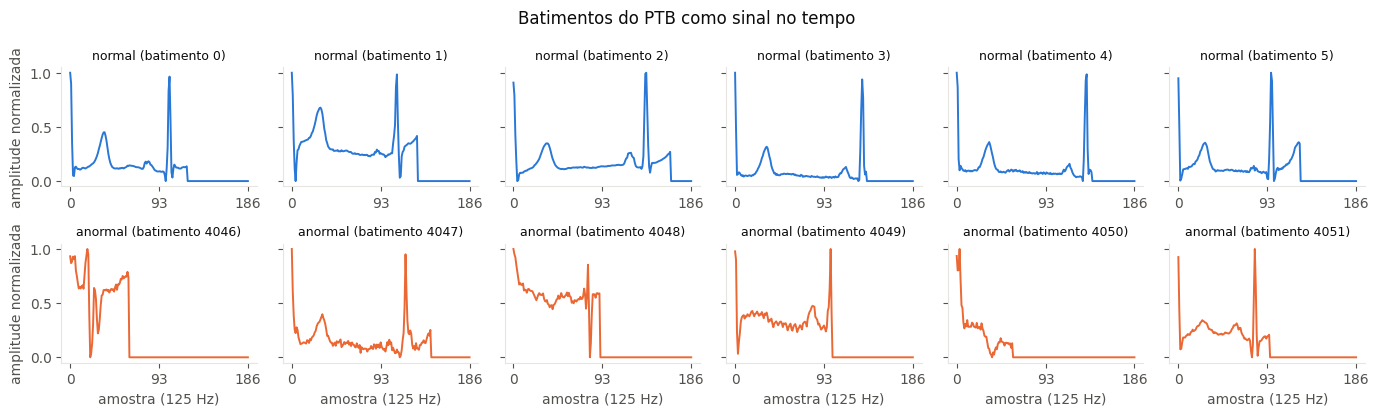

In [4]:
# Seis primeiros batimentos de cada classe, desenhados como sinal no tempo
fig, eixos = plt.subplots(2, 6, figsize=(14, 4.2), sharey=True)
for linha, (rotulo, nome) in enumerate([(0, "normal"), (1, "anormal")]):
    indices = np.flatnonzero(y == rotulo)[:6]  # indices dos primeiros batimentos da classe
    for coluna, i in enumerate(indices):
        eixo = eixos[linha, coluna]
        eixo.plot(X_sinal[i], color=CORES[nome], linewidth=1.4)
        eixo.set_title(f"{nome} (batimento {i})", fontsize=9)
        eixo.set_xticks([0, 93, 186])
        if coluna == 0:
            eixo.set_ylabel("amplitude normalizada")
        if linha == 1:
            eixo.set_xlabel("amostra (125 Hz)")
fig.suptitle("Batimentos do PTB como sinal no tempo", color=TEXTO)
fig.tight_layout()
fig.savefig(DIR_ASSETS / "exemplos_batimentos.png", bbox_inches="tight")
plt.show()

## 4. Dos sinais às imagens em tons de cinza

Cada batimento é desenhado como o traçado de um gráfico de linha em um quadro quadrado de 96 x 96 pixels, com fundo preto (0) e traço branco (255), terminando na última amostra não nula. O resultado é uma imagem em tons de cinza de um canal, como as de um exame impresso digitalizado, e é esse conjunto de imagens que entra na etapa de pré-processamento pedida pelo enunciado. Vinte exemplos (dez por classe) são gravados em PNG em `assets/exemplos_imagens/`, para que o repositório contenha imagens reais do pipeline.

A célula seguinte define `batimentos_para_imagens` (conversão vetorizada do lote de sinais em imagens) e `salvar_exemplos` (gravação dos PNG); a célula posterior aplica as duas funções a todos os batimentos.

In [5]:
# Conversao sinal -> imagem: desenha cada batimento como o traco de um grafico em um quadro de LADO_IMAGEM x LADO_IMAGEM pixels
def batimentos_para_imagens(X, lado=LADO_IMAGEM, espessura=ESPESSURA):
    """Converte um lote de batimentos (n, 187) em imagens em tons de cinza
    (n, lado, lado) com valores 0 (fundo) e 255 (traco).

    O tracado e desenhado como em um grafico de linha: cada coluna da imagem
    recebe um segmento vertical entre a amplitude da coluna anterior e a da
    coluna atual, o que mantem a linha continua. Operacao vetorizada por
    coluna, para que o lote inteiro seja convertido em poucos segundos.
    """
    n = X.shape[0]
    posicoes = np.linspace(0, X.shape[1] - 1, lado)
    indices = np.arange(X.shape[1])
    # Interpola a amplitude de cada batimento nas `lado` colunas da imagem
    amplitudes = np.vstack([np.interp(posicoes, indices, sinal) for sinal in X])
    linhas = np.rint((1.0 - np.clip(amplitudes, 0.0, 1.0)) * (lado - 1)).astype(np.int32)  # amplitude alta = topo
    # O dataset preenche o fim de cada batimento com zeros ate 187 amostras; o traco
    # termina na ultima amostra nao nula, de modo que a duracao do batimento fica
    # visivel na imagem em vez de virar uma linha reta no fundo.
    ultima_amostra = np.array([np.flatnonzero(sinal > 0).max() if np.any(sinal > 0) else 0 for sinal in X])
    ultima_coluna = np.floor(ultima_amostra / (X.shape[1] - 1) * (lado - 1)).astype(np.int32)
    imagens = np.zeros((n, lado, lado), dtype=np.uint8)
    grade = np.arange(lado)[None, :]
    for coluna in range(lado):
        anterior = linhas[:, max(coluna - 1, 0)]
        atual = linhas[:, coluna]
        inferior = np.minimum(anterior, atual)[:, None]
        superior = np.maximum(anterior, atual)[:, None]
        ativo = (coluna <= ultima_coluna)[:, None]
        mascara = (grade >= inferior) & (grade <= superior) & ativo
        imagens[:, :, coluna] = np.where(mascara, 255, 0)
    # Engrossa o traco deslocando a imagem uma linha para baixo e combinando
    for _ in range(max(espessura - 1, 0)):
        deslocada = np.zeros_like(imagens)
        deslocada[:, 1:, :] = imagens[:, :-1, :]
        imagens = np.maximum(imagens, deslocada)
    return imagens


def salvar_exemplos(imagens, y, pasta=PASTA_EXEMPLOS, por_classe=10):
    """Grava `por_classe` imagens PNG de cada classe (os primeiros batimentos
    de cada rotulo) em `pasta`. Devolve a lista de caminhos gravados."""
    os.makedirs(pasta, exist_ok=True)
    caminhos = []
    for rotulo, nome in [(0, "normal"), (1, "anormal")]:
        indices = np.flatnonzero(y == rotulo)[:por_classe]
        for k, i in enumerate(indices, 1):
            caminho = os.path.join(pasta, f"{nome}_{k:02d}.png")
            Image.fromarray(imagens[i], mode="L").save(caminho)
            caminhos.append(caminho)
    return caminhos

Imagens geradas: (14552, 96, 96) (n, altura, largura), dtype uint8, em 2.1 s
20 exemplos gravados em assets/exemplos_imagens/ (PNG, modo L, 96x96)


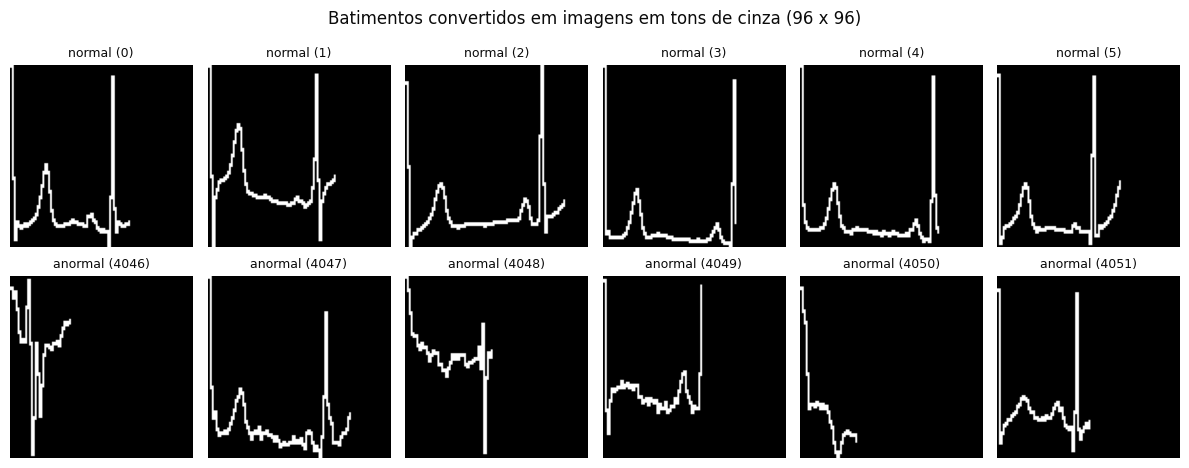

In [6]:
# Converte todos os batimentos em imagens 96 x 96 em tons de cinza (0 = fundo, 255 = traco)
t0 = time.time()
imagens = batimentos_para_imagens(X_sinal, lado=LADO_IMAGEM, espessura=ESPESSURA)
print(f"Imagens geradas: {imagens.shape} (n, altura, largura), dtype {imagens.dtype}, em {time.time() - t0:.1f} s")

# Grava 10 exemplos de cada classe em PNG, para que o repositorio contenha imagens reais do pipeline
selecao = np.concatenate([np.flatnonzero(y == 0)[:10], np.flatnonzero(y == 1)[:10]])
caminhos_exemplos = salvar_exemplos(imagens[selecao], y[selecao], pasta=PASTA_EXEMPLOS, por_classe=10)
print(f"{len(caminhos_exemplos)} exemplos gravados em assets/exemplos_imagens/ (PNG, modo L, {LADO_IMAGEM}x{LADO_IMAGEM})")

# Mostra as mesmas seis amostras de cada classe, agora como imagem
fig, eixos = plt.subplots(2, 6, figsize=(12, 4.9))
for linha, (rotulo, nome) in enumerate([(0, "normal"), (1, "anormal")]):
    for coluna, i in enumerate(np.flatnonzero(y == rotulo)[:6]):
        eixos[linha, coluna].imshow(imagens[i], cmap="gray", vmin=0, vmax=255)
        eixos[linha, coluna].set_title(f"{nome} ({i})", fontsize=9)
        eixos[linha, coluna].axis("off")
fig.suptitle("Batimentos convertidos em imagens em tons de cinza (96 x 96)", color=TEXTO)
fig.tight_layout()
fig.savefig(DIR_ASSETS / "exemplos_imagens.png", bbox_inches="tight")
plt.show()

## 5. Pré-processamento das imagens

Para cada imagem: conversão para tons de cinza (modo `L` do Pillow, um canal), **redimensionamento para 32 x 32 pixels** (reamostragem bilinear), normalização para o intervalo 0 a 1 e achatamento em um vetor de 1.024 posições, que é o formato de entrada de uma MLP (a rede não recebe a grade 2D, apenas o vetor). O redimensionamento reduz 9.216 pixels a 1.024, o que acelera o treinamento e limita o número de parâmetros, ao custo de detalhes finos do traçado.

A primeira célula define `imagem_para_vetor` (o pré-processamento de uma imagem: tons de cinza, 32 x 32, intervalo 0 a 1, vetor), `imagens_para_vetores` (aplicação ao lote) e `carregar_pasta_de_imagens` (leitura de PNG em disco). A segunda aplica o pré-processamento a todas as imagens e também o demonstra a partir dos arquivos PNG gravados em `assets/exemplos_imagens/`, para mostrar que ele funciona com imagens em disco, não apenas com arrays em memória.

In [7]:
# Pre-processamento das imagens para a rede: tons de cinza ('L'), redimensionamento para LADO_REDE x LADO_REDE, [0, 1] e vetor
def imagem_para_vetor(imagem, lado=LADO_REDE):
    """Pre-processamento de uma imagem para a rede: converte para tons de
    cinza ('L'), redimensiona para lado x lado, normaliza para [0, 1] e achata.
    Aceita um array numpy ou um objeto PIL.Image."""
    if not isinstance(imagem, Image.Image):
        imagem = Image.fromarray(np.asarray(imagem, dtype=np.uint8))
    imagem = imagem.convert("L").resize((lado, lado), Image.Resampling.BILINEAR)
    return (np.asarray(imagem, dtype=np.float32) / 255.0).reshape(-1)


def imagens_para_vetores(imagens, lado=LADO_REDE):
    """Aplica `imagem_para_vetor` a um lote (n, altura, largura) e devolve (n, lado*lado)."""
    return np.vstack([imagem_para_vetor(img, lado) for img in imagens])


def carregar_pasta_de_imagens(pasta, lado=LADO_REDE):
    """Carrega todos os PNGs de uma pasta como vetores (uso ilustrativo: mostra
    que o pipeline funciona a partir de arquivos de imagem, nao so de arrays)."""
    nomes = sorted(n for n in os.listdir(pasta) if n.lower().endswith(".png"))
    vetores = [imagem_para_vetor(Image.open(os.path.join(pasta, n)), lado) for n in nomes]
    rotulos = np.array([0 if n.startswith("normal") else 1 for n in nomes])
    return np.vstack(vetores), rotulos, nomes

Matriz de entrada: (14552, 1024) (n, 32x32) | valores de 0.00 a 1.00 | 0.9 s
Lidos de assets/exemplos_imagens/: 20 arquivos PNG -> vetores (20, 1024) | rotulos [10 10]


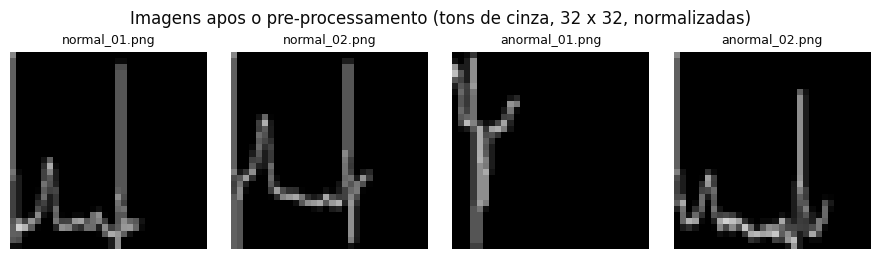

In [8]:
# Aplica o pre-processamento a todas as imagens em memoria: matriz (n, 1024) pronta para a MLP
t0 = time.time()
X_img = imagens_para_vetores(imagens, lado=LADO_REDE)
print(f"Matriz de entrada: {X_img.shape} (n, {LADO_REDE}x{LADO_REDE}) | valores de {X_img.min():.2f} a {X_img.max():.2f} | {time.time() - t0:.1f} s")

# O mesmo pipeline a partir dos arquivos PNG em disco (prova de que funciona com imagens, nao so com arrays)
X_png, y_png, nomes_png = carregar_pasta_de_imagens(PASTA_EXEMPLOS, lado=LADO_REDE)
print(f"Lidos de assets/exemplos_imagens/: {X_png.shape[0]} arquivos PNG -> vetores {X_png.shape} | rotulos {np.bincount(y_png)}")

# Visualiza quatro imagens apos o redimensionamento para 32 x 32 (o que a rede realmente recebe)
fig, eixos = plt.subplots(1, 4, figsize=(9, 2.6))
for eixo, nome in zip(eixos, ["normal_01.png", "normal_02.png", "anormal_01.png", "anormal_02.png"]):
    vetor = X_png[nomes_png.index(nome)]
    eixo.imshow(vetor.reshape(LADO_REDE, LADO_REDE), cmap="gray", vmin=0, vmax=1)
    eixo.set_title(nome, fontsize=9)
    eixo.axis("off")
fig.suptitle("Imagens apos o pre-processamento (tons de cinza, 32 x 32, normalizadas)", color=TEXTO)
fig.tight_layout()
plt.show()

## 6. Divisão treino, validação e teste

Divisão estratificada em 70% treino, 15% validação e 15% teste, com semente fixa. A validação serve para a parada antecipada (`EarlyStopping`); o teste é usado uma única vez, ao final. Como a classe anormal é a maioria (72%), o treinamento usa pesos de classe inversamente proporcionais à frequência, para que a rede não aprenda a responder "anormal" por padrão.

Limitação importante: o dataset não traz o identificador do paciente, e batimentos de um mesmo paciente podem cair em partições diferentes. Isso tende a tornar as métricas otimistas em relação a pacientes nunca vistos.

In [9]:
# 70% treino; os 30% restantes divididos ao meio em validacao (15%) e teste (15%), mantendo a proporcao das classes
X_treino, X_temp, y_treino, y_temp = train_test_split(X_img, y, test_size=0.30, stratify=y, random_state=SEMENTE)
X_val, X_teste, y_val, y_teste = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEMENTE)
# As mesmas particoes para o sinal bruto (comparacao da secao 10), usando os mesmos indices
idx = np.arange(len(y))
idx_treino, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEMENTE)
idx_val, idx_teste = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp], random_state=SEMENTE)
assert np.array_equal(y[idx_teste], y_teste)

# Pesos inversamente proporcionais a frequencia de cada classe (compensa os 72% de batimentos anormais)
pesos_classe = {0: len(y_treino) / (2 * (y_treino == 0).sum()), 1: len(y_treino) / (2 * (y_treino == 1).sum())}
for nome, alvo in [("treino", y_treino), ("validacao", y_val), ("teste", y_teste)]:
    print(f"{nome:10s}: {len(alvo):6d} batimentos | normal {np.sum(alvo == 0):5d} | anormal {np.sum(alvo == 1):5d}")
print("Pesos de classe:", {k: round(v, 3) for k, v in pesos_classe.items()})

treino    :  10186 batimentos | normal  2832 | anormal  7354
validacao :   2183 batimentos | normal   607 | anormal  1576
teste     :   2183 batimentos | normal   607 | anormal  1576
Pesos de classe: {0: np.float64(1.798), 1: np.float64(0.693)}


## 7. A rede MLP em Keras

Arquitetura sequencial: entrada de 1.024 valores, duas camadas densas ocultas com ativação ReLU (256 e 128 neurônios), `Dropout` de 0,3 após cada uma para reduzir o sobreajuste, e uma saída com um neurônio e ativação `sigmoid`, que devolve a probabilidade de o batimento ser anormal. Função de perda `binary_crossentropy`, otimizador Adam, métricas de acurácia e AUC.

In [10]:
def construir_mlp(dim_entrada, nome):
    """Monta e compila a MLP: entrada achatada, duas camadas densas com ReLU e Dropout, saida sigmoid."""
    modelo = keras.Sequential([
        layers.Input(shape=(dim_entrada,), name="entrada"),
        layers.Dense(256, activation="relu", name="oculta_1"),
        layers.Dropout(0.3, name="dropout_1"),
        layers.Dense(128, activation="relu", name="oculta_2"),
        layers.Dropout(0.3, name="dropout_2"),
        layers.Dense(1, activation="sigmoid", name="saida"),  # probabilidade de batimento anormal
    ], name=nome)
    # Perda para classificacao binaria; acuracia e AUC acompanhadas durante o treino
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="binary_crossentropy",
                   metrics=[keras.metrics.BinaryAccuracy(name="acuracia"), keras.metrics.AUC(name="auc")])
    return modelo


mlp_imagens = construir_mlp(X_img.shape[1], "mlp_ecg_imagens")  # 1.024 entradas (32 x 32)
mlp_imagens.summary()

Model: "mlp_ecg_imagens"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,425 (1.13 MB)

 Trainable params: 295,425 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Treinamento

Até 60 épocas, lotes de 128 batimentos, pesos de classe e `EarlyStopping` monitorando a perda de validação (paciência de 6 épocas, restaurando os melhores pesos). As curvas de perda e acurácia são gravadas em `assets/curvas_treino.png`.

Epoch 18: early stopping


Restoring model weights from the end of the best epoch: 12.


Treinamento concluido em 13.1 s | epocas executadas: 18 | melhor epoca (val_loss): 12
Perda de validacao minima: 0.0897 | acuracia de validacao na melhor epoca: 0.9739


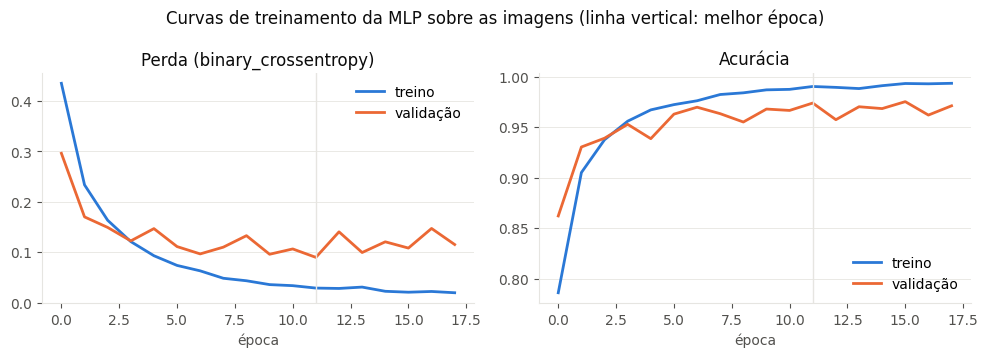

In [11]:
# Parada antecipada: interrompe quando a perda de validacao para de melhorar por 6 epocas e restaura os melhores pesos
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1)
t0 = time.time()
historico = mlp_imagens.fit(X_treino, y_treino, validation_data=(X_val, y_val), epochs=60, batch_size=128,
                            class_weight=pesos_classe, callbacks=[parada], verbose=0)
epocas_executadas = len(historico.history["loss"])
melhor_epoca = int(np.argmin(historico.history["val_loss"])) + 1  # epoca de menor perda de validacao
print(f"Treinamento concluido em {time.time() - t0:.1f} s | epocas executadas: {epocas_executadas} | melhor epoca (val_loss): {melhor_epoca}")
print(f"Perda de validacao minima: {min(historico.history['val_loss']):.4f} | acuracia de validacao na melhor epoca: {historico.history['val_acuracia'][melhor_epoca - 1]:.4f}")

# Curvas de treino e validacao (perda e acuracia por epoca)
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.6))
for eixo, chave, titulo in [(eixos[0], "loss", "Perda (binary_crossentropy)"), (eixos[1], "acuracia", "Acurácia")]:
    eixo.plot(historico.history[chave], color=CORES["normal"], linewidth=2, label="treino")
    eixo.plot(historico.history["val_" + chave], color=CORES["anormal"], linewidth=2, label="validação")
    eixo.axvline(melhor_epoca - 1, color=GRADE, linewidth=1)
    eixo.set_xlabel("época")
    eixo.set_title(titulo)
    eixo.grid(axis="y", color=GRADE, linewidth=0.6)
    eixo.legend(frameon=False)
fig.suptitle("Curvas de treinamento da MLP sobre as imagens (linha vertical: melhor época)", color=TEXTO)
fig.tight_layout()
fig.savefig(DIR_ASSETS / "curvas_treino.png", bbox_inches="tight")
plt.show()

## 9. Avaliação no conjunto de teste

Acurácia, AUC, matriz de confusão e relatório de classificação. Em um contexto de triagem, a métrica a observar com mais cuidado é a **sensibilidade da classe anormal** (quantos batimentos anormais o modelo reconhece), porque o falso negativo é o erro mais custoso.

Acuracia no teste: 0.9734 | AUC: 0.9948 | sensibilidade (anormal): 0.9778 | especificidade (normal): 0.9621
Linha de base (prever sempre 'anormal'): acuracia 0.7219
Matriz de confusao (linhas: real normal, anormal; colunas: previsto normal, anormal): [[584, 23], [35, 1541]]
Verdadeiros negativos 584 | falsos positivos 23 | falsos negativos 35 | verdadeiros positivos 1541

              precision    recall  f1-score   support

      normal     0.9435    0.9621    0.9527       607
     anormal     0.9853    0.9778    0.9815      1576

    accuracy                         0.9734      2183
   macro avg     0.9644    0.9700    0.9671      2183
weighted avg     0.9737    0.9734    0.9735      2183



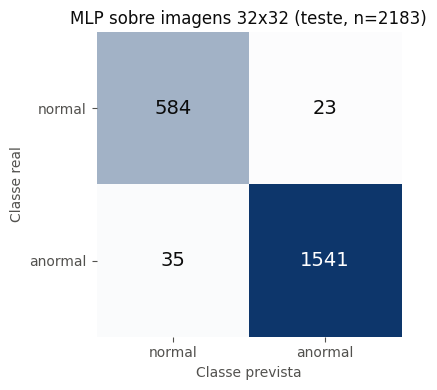

Modelo gravado em src/models/mlp_ecg_imagens.keras


In [12]:
# Probabilidades no conjunto de teste (usado uma unica vez) e classe prevista com limiar 0,5
prob_teste = mlp_imagens.predict(X_teste, verbose=0).ravel()
pred_teste = (prob_teste >= 0.5).astype(int)
acuracia_img = accuracy_score(y_teste, pred_teste)
auc_img = roc_auc_score(y_teste, prob_teste)
matriz = confusion_matrix(y_teste, pred_teste, labels=[0, 1])  # linhas: classe real; colunas: classe prevista
sens_anormal_img = matriz[1, 1] / matriz[1].sum()  # sensibilidade: anormais reconhecidos
espec_img = matriz[0, 0] / matriz[0].sum()         # especificidade: normais reconhecidos
print(f"Acuracia no teste: {acuracia_img:.4f} | AUC: {auc_img:.4f} | sensibilidade (anormal): {sens_anormal_img:.4f} | especificidade (normal): {espec_img:.4f}")
print(f"Linha de base (prever sempre 'anormal'): acuracia {y_teste.mean():.4f}")
print(f"Matriz de confusao (linhas: real normal, anormal; colunas: previsto normal, anormal): {matriz.tolist()}")
print(f"Verdadeiros negativos {matriz[0, 0]} | falsos positivos {matriz[0, 1]} | falsos negativos {matriz[1, 0]} | verdadeiros positivos {matriz[1, 1]}")
print()
print(classification_report(y_teste, pred_teste, target_names=["normal", "anormal"], digits=4))

# Matriz de confusao como figura (tambem gravada em assets/)
fig, eixo = plt.subplots(figsize=(4.4, 4))
mapa_azul = matplotlib.colors.LinearSegmentedColormap.from_list("azul", ["#ffffff", "#0d366b"])
eixo.imshow(matriz, cmap=mapa_azul, vmin=0, vmax=matriz.max())
for i in range(2):
    for j in range(2):
        eixo.text(j, i, matriz[i, j], ha="center", va="center", fontsize=14, color="white" if matriz[i, j] > matriz.max() / 2 else TEXTO)
eixo.set_xticks([0, 1], ["normal", "anormal"])
eixo.set_yticks([0, 1], ["normal", "anormal"])
eixo.set_xlabel("Classe prevista")
eixo.set_ylabel("Classe real")
eixo.set_title(f"MLP sobre imagens 32x32 (teste, n={len(y_teste)})")
eixo.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(DIR_ASSETS / "matriz_confusao.png", bbox_inches="tight")
plt.show()

mlp_imagens.save(DIR_MODELOS / "mlp_ecg_imagens.keras")  # modelo treinado, no formato nativo do Keras 3
print("Modelo gravado em src/models/mlp_ecg_imagens.keras")

## 10. Comparação: a mesma MLP sobre o sinal numérico original

Para medir o que se perde (ou não) ao transformar o sinal em imagem, a mesma arquitetura é treinada com os 187 valores do batimento como entrada, com as mesmas partições, pesos de classe e critério de parada.

In [13]:
# Mesmas particoes (mesmos indices), agora com os 187 valores do sinal como entrada
X_sinal_treino, X_sinal_val, X_sinal_teste = X_sinal[idx_treino], X_sinal[idx_val], X_sinal[idx_teste]
mlp_sinal = construir_mlp(X_sinal.shape[1], "mlp_ecg_sinal")
t0 = time.time()
hist_sinal = mlp_sinal.fit(X_sinal_treino, y_treino, validation_data=(X_sinal_val, y_val), epochs=60, batch_size=128,
                           class_weight=pesos_classe, callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)], verbose=0)
prob_sinal = mlp_sinal.predict(X_sinal_teste, verbose=0).ravel()
pred_sinal = (prob_sinal >= 0.5).astype(int)
matriz_sinal = confusion_matrix(y_teste, pred_sinal, labels=[0, 1])
print(f"MLP sobre o sinal: {len(hist_sinal.history['loss'])} epocas em {time.time() - t0:.1f} s")

# Tabela comparativa: imagem, sinal bruto e linha de base (sempre prever a classe majoritaria)
comparacao = pd.DataFrame([
    {"entrada": "imagem 32x32 em tons de cinza (1.024 valores)", "acurácia teste": acuracia_img, "AUC": auc_img,
     "sensibilidade anormal": sens_anormal_img, "especificidade normal": espec_img, "parâmetros": mlp_imagens.count_params()},
    {"entrada": "sinal original (187 valores)", "acurácia teste": accuracy_score(y_teste, pred_sinal), "AUC": roc_auc_score(y_teste, prob_sinal),
     "sensibilidade anormal": matriz_sinal[1, 1] / matriz_sinal[1].sum(), "especificidade normal": matriz_sinal[0, 0] / matriz_sinal[0].sum(), "parâmetros": mlp_sinal.count_params()},
    {"entrada": "linha de base: sempre anormal", "acurácia teste": y_teste.mean(), "AUC": 0.5, "sensibilidade anormal": 1.0, "especificidade normal": 0.0, "parâmetros": 0},
]).set_index("entrada")
display(comparacao.round(4))

MLP sobre o sinal: 27 epocas em 12.7 s


,acurácia teste,AUC,sensibilidade anormal,especificidade normal,parâmetros
entrada,,,,,
imagem 32x32 em tons de cinza (1.024 valores),0.9734,0.9948,0.9778,0.9621,295425
sinal original (187 valores),0.9482,0.9830,0.9467,0.9522,81153
linha de base: sempre anormal,0.7219,0.5000,1.0000,0.0000,0


## 11. Sensibilidade ao limiar de decisão

O limiar padrão de 0,5 equilibra os dois tipos de erro. Em triagem, pode-se deslocá-lo para reduzir falsos negativos (batimentos anormais classificados como normais) ao custo de mais falsos positivos. A tabela mostra o efeito no conjunto de teste para a MLP sobre imagens.

In [14]:
# Recalcula as metricas do teste para varios limiares de decisao (sem retreinar)
linhas = []
for limiar in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (prob_teste >= limiar).astype(int)
    m = confusion_matrix(y_teste, pred, labels=[0, 1])
    linhas.append({"limiar": limiar, "acurácia": accuracy_score(y_teste, pred), "sensibilidade anormal": m[1, 1] / m[1].sum(),
                   "especificidade normal": m[0, 0] / m[0].sum(), "falsos negativos": int(m[1, 0]), "falsos positivos": int(m[0, 1])})
display(pd.DataFrame(linhas).set_index("limiar").round(4))

,acurácia,sensibilidade anormal,especificidade normal,falsos negativos,falsos positivos
limiar,,,,,
0.3,0.9734,0.9848,0.9440,24,34
0.4,0.9743,0.9810,0.9572,30,26
0.5,0.9734,0.9778,0.9621,35,23
0.6,0.9743,0.9759,0.9703,38,18
0.7,0.9702,0.9670,0.9786,52,13


## 12. Conclusões, limitações e ética

### 12.1 O que os resultados mostram

| Medida (conjunto de teste, 2.183 batimentos) | MLP sobre imagens 32 x 32 | MLP sobre o sinal original | Linha de base (sempre anormal) |
|---|---|---|---|
| Acurácia | 0,9734 | 0,9482 | 0,7219 |
| AUC | 0,9948 | 0,9830 | 0,5000 |
| Sensibilidade da classe anormal | 0,9778 | 0,9467 | 1,0000 |
| Especificidade da classe normal | 0,9621 | 0,9522 | 0,0000 |
| Parâmetros treináveis | 295.425 | 81.153 | 0 |

- A MLP treinada sobre as imagens acertou 97,34% dos batimentos de teste, com AUC de 0,9948; a matriz de confusão registra 584 normais e 1.541 anormais corretamente classificados, 23 falsos positivos e 35 falsos negativos. A acurácia está bem acima dos 72,19% da linha de base, o que confirma que a rede aprendeu o traçado, e não apenas a proporção das classes.
- A parada antecipada interrompeu o treinamento na época 18 e restaurou os pesos da época 12, a de menor perda de validação (0,0897). As curvas mostram a perda de treino caindo continuamente enquanto a de validação estabiliza a partir da sexta época: é o início do sobreajuste, que o `Dropout` e a parada antecipada contiveram.
- A versão sobre o sinal numérico, com a mesma arquitetura e as mesmas partições, ficou em 94,82% de acurácia. O resultado mostra que a conversão em imagem não destruiu a informação clínica do batimento; a vantagem da versão em imagem é uma inferência deste experimento específico (a representação em pixels espalha a amplitude de cada instante por várias linhas da imagem, o que parece facilitar a separação linear das camadas densas), e não uma propriedade geral: com outras arquiteturas, em especial as convolucionais, o sinal bruto costuma ser a entrada mais eficiente.
- A tabela de limiares mostra a troca entre os dois erros: baixar o limiar para 0,3 reduz os falsos negativos de 35 para 24 ao custo de 34 falsos positivos; subir para 0,7 faz o oposto (52 falsos negativos, 13 falsos positivos). Em uma triagem, em que deixar passar um batimento anormal é o erro mais grave, um limiar abaixo de 0,5 seria o ajuste coerente, e essa escolha pertence à equipe clínica, não ao modelo.

### 12.2 Limitações

- **Sem separação por paciente.** O dataset não identifica o paciente de cada batimento; batimentos da mesma pessoa podem estar no treino e no teste ao mesmo tempo, o que torna as métricas otimistas em relação a pacientes nunca vistos. É a limitação mais importante deste trabalho.
- **Imagens sintetizadas a partir do sinal.** As imagens não são digitalizações de exames impressos; são traçados desenhados pelo próprio pipeline, limpos, alinhados pela onda R e sem ruído de papel, grade ou rotação. Um modelo treinado assim não está pronto para fotografias ou digitalizações de ECG reais.
- **Significado do rótulo "anormal".** Segundo os autores da segmentação (Kachuee, Fazeli e Sarrafzadeh, 2018), o subconjunto PTB utilizado reúne controles saudáveis e pacientes com infarto do miocárdio; o rótulo binário não distingue tipos de anomalia, e um modelo treinado nele não generaliza, por si, para arritmias ou outras condições cardíacas.
- **MLP ignora a vizinhança espacial.** Ao achatar a imagem em um vetor, a rede perde a noção de quais pixels são vizinhos; redes convolucionais são a escolha natural para imagens e tendem a superar a MLP com menos parâmetros.
- **Redimensionamento agressivo.** De 96 x 96 para 32 x 32 pixels, detalhes finos do traçado se perdem; o custo computacional menor foi preferido por se tratar de uma MLP didática.
- **Uma única semente e uma única divisão.** Os números são de uma execução com `SEMENTE = 42`; repetições com outras sementes ou validação cruzada dariam a variabilidade das métricas.

### 12.3 Ética, LGPD e uso responsável

- Os dados são públicos, anonimizados na origem (PhysioNet, PTB Diagnostic ECG Database) e redistribuídos para fins de pesquisa; nenhuma informação pessoal foi tratada. Com dados reais de pacientes brasileiros, o tratamento exigiria base legal específica para dados de saúde (LGPD, art. 11), anonimização ou pseudonimização, consentimento ou tutela da saúde, governança de acesso e registro das decisões do modelo.
- O modelo é um exercício acadêmico de classificação binária. Não é dispositivo médico, não foi validado clinicamente e não substitui a leitura do eletrocardiograma por um profissional de saúde; em qualquer uso prático, a saída seria apenas um sinal de priorização, sob supervisão humana e com registro das decisões.
- Um falso negativo (batimento anormal classificado como normal) é o erro de maior custo em triagem, e foi tratado como tal: a sensibilidade da classe anormal é acompanhada ao lado da acurácia, e a seção 11 mostra como o limiar pode ser ajustado para reduzi-lo.

### 12.4 Próximos passos

Separação por paciente (quando houver identificador), validação cruzada com várias sementes, comparação com uma rede convolucional sobre as mesmas imagens, aumento de dados que simule ruído e rotação de exames digitalizados, e integração do resultado ao fluxo de triagem textual da Fase 2 (extração de sintomas e classificação de risco), para que o CardioIA combine texto e sinal em uma mesma fila de prioridade.

## 13. Referências

- BOUSSELJOT, R.; KREISELER, D.; SCHNABEL, A. Nutzung der EKG-Signaldatenbank CARDIODAT der PTB über das Internet. **Biomedizinische Technik**, v. 40, supl. 1, p. 317-318, 1995. (PTB Diagnostic ECG Database.)
- CHOLLET, F. et al. **Keras**. 2015. Disponível em: https://keras.io/. Acesso em: 2 out. 2026.
- FAZELI, S. **ECG Heartbeat Categorization Dataset** [conjunto de dados]. Kaggle, 2018. Disponível em: https://www.kaggle.com/datasets/shayanfazeli/heartbeat. Acesso em: 2 out. 2026.
- FIAP. **Máquinas que enxergam: filtragem inteligente de imagens com IA**. Capítulo 12 do material didático da Fase 2, 2º ano, curso de Inteligência Artificial. São Paulo: FIAP, 2025.
- GOLDBERGER, A. L. et al. PhysioBank, PhysioToolkit, and PhysioNet: components of a new research resource for complex physiologic signals. **Circulation**, v. 101, n. 23, p. e215-e220, 2000. DOI: 10.1161/01.CIR.101.23.e215.
- KACHUEE, M.; FAZELI, S.; SARRAFZADEH, M. ECG heartbeat classification: a deep transferable representation. In: IEEE INTERNATIONAL CONFERENCE ON HEALTHCARE INFORMATICS (ICHI), 2018, Nova York. **Proceedings** [...]. IEEE, 2018. p. 443-444. DOI: 10.1109/ICHI.2018.00092.
- PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. **Journal of Machine Learning Research**, v. 12, p. 2825-2830, 2011.